## 00-EDA Exploratory Data Analysis



In [193]:
# import required packages
import pandas as pd
import os
import re
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [194]:
# labels
# AD = Alzheimer's Disease (positive class)
# CN = Cognitively Normal (negative class)

In [195]:
path_ad = "../data/Transcribed Data-2024-Feb-13/Diagnosis Training Data/ad transcribed/"
path_cn = (
    "../data/Transcribed Data-2024-Feb-13//Diagnosis Training Data/cn transcribed/"
)
mmse_scores_fname = "../data/Training Dataset/Diagnosis training data/ADReSSo21/diagnosis/train/adresso-train-mmse-scores.csv"

In [196]:
train_data = {"ad": [], "cn": []}

In [197]:
def line_clean(line):
    """
    Clean line from extra information like "*PAR: ", "\x1530_5640\x15", etc
    """
    result = line
    if result.startswith("*PAR"):
        result = result.replace("*PAR:\t", "")
        result = re.sub(".*", "", result)
        result = re.sub("\[.*\]", "", result)
        result = result.strip("&-+<").strip()
    else:
        result = ""
    return result


s = "*PAR:\tthe scene is <in the> [/] in the kitchen . \x1530_5640\x15\n"
assert line_clean(s) == "the scene is <in the>  in the kitchen ."

In [198]:
def read_data(path, format, pitt_corpus=False):
    """
    get data from "txt" files from a specified folder (ad/cn)
    returns list of text (strings)
    """
    result = []
    # get only txt files
    files = sorted([item for item in os.listdir(path) if item.endswith(format)])

    for fname in files:
        print("Processing files =", fname)  # , end="\r")
        with open(path + fname, encoding="utf-8") as f:
            lines = f.readlines()
            print("Line len =", len(lines))  # , end="\r")
            if pitt_corpus:
                lines = [line_clean(line) for line in lines if line.startswith("*PAR")]
            text = "\n".join(lines)
            result.append((fname.split(".txt")[0], text))

    return result

In [199]:
format = "txt"
train_data["ad"] = read_data(path_ad, format)
train_data["cn"] = read_data(path_cn, format)

Processing files = adrso024.txt
Line len = 23
Processing files = adrso025.txt
Line len = 13
Processing files = adrso027.txt
Line len = 9
Processing files = adrso028.txt
Line len = 17
Processing files = adrso031.txt
Line len = 29
Processing files = adrso032.txt
Line len = 5
Processing files = adrso033.txt
Line len = 7
Processing files = adrso035.txt
Line len = 9
Processing files = adrso036.txt
Line len = 21
Processing files = adrso039.txt
Line len = 9
Processing files = adrso043.txt
Line len = 27
Processing files = adrso045.txt
Line len = 35
Processing files = adrso046.txt
Line len = 13
Processing files = adrso047.txt
Line len = 3
Processing files = adrso049.txt
Line len = 15
Processing files = adrso053.txt
Line len = 21
Processing files = adrso054.txt
Line len = 21
Processing files = adrso055.txt
Line len = 9
Processing files = adrso056.txt
Line len = 29
Processing files = adrso059.txt
Line len = 3
Processing files = adrso060.txt
Line len = 19
Processing files = adrso063.txt
Line len =

In [200]:
mmse_df = pd.read_csv(mmse_scores_fname, usecols=["adressfname", "mmse", "dx"])
mmse_df

,adressfname,mmse,dx
0,adrso024,20,ad
1,adrso025,11,ad
2,adrso027,18,ad
3,adrso028,18,ad
4,adrso031,26,ad
...,...,...,...
161,adrso309,30,cn
162,adrso310,28,cn
163,adrso312,29,cn
164,adrso315,28,cn


In [201]:
train_data["ad"]

[('adrso024',
  "The cookie jar and the little\n\n\n\nboy about down on the floor\n\n\n\ngirls\n\n\n\nGirls anyway the housewife\n\n\n\nsink is overflowing\n\n\n\ngirl may be saying say ha ha ha I told you so or something like that\n\n\n\nI guess this must be the wife although it might not be because maybe that was an apron and maybe this was\n\n\n\na various\n\n\n\nthis should be a window there Yepper was there as a pathway we don't know where the pathway is going to because we can't see it\n\n\n\nbelow and looks like there's some flowers in the bushes or something like that. And here some great breeze well this one on this side is I see it the other side I suspect it would be the same thing there. And the I guess I said the water was coming down on the floor\n\n\n\nthere are two cup cup cups for coffee or something like that and that's fine\n\n\n\nokay, thank you very much\n"),
 ('adrso025',
  "Tell me everything that's going on\n\n\n\nthe kids are\n\n\n\ngrading and they are going t

In [202]:
# double check data
assert len(train_data["ad"]) == 87
assert len(train_data["cn"]) == 79
assert train_data["ad"][0][1].startswith("The cookie jar and the little")
assert train_data["ad"][1][1].startswith("Tell me everything that's going on")
assert train_data["cn"][0][1].startswith("Okay, I see a mom doing")
assert train_data["cn"][1][1].startswith("Starting from the left I see")
print("Passed")

Passed


In [203]:
# take a look at the data
print(train_data["ad"][0][:100])

('adrso024', "The cookie jar and the little\n\n\n\nboy about down on the floor\n\n\n\ngirls\n\n\n\nGirls anyway the housewife\n\n\n\nsink is overflowing\n\n\n\ngirl may be saying say ha ha ha I told you so or something like that\n\n\n\nI guess this must be the wife although it might not be because maybe that was an apron and maybe this was\n\n\n\na various\n\n\n\nthis should be a window there Yepper was there as a pathway we don't know where the pathway is going to because we can't see it\n\n\n\nbelow and looks like there's some flowers in the bushes or something like that. And here some great breeze well this one on this side is I see it the other side I suspect it would be the same thing there. And the I guess I said the water was coming down on the floor\n\n\n\nthere are two cup cup cups for coffee or something like that and that's fine\n\n\n\nokay, thank you very much\n")


In [204]:
# take a look at the data
print(train_data["cn"][0][:100])

('adrso002', "Okay, I see a mom doing the dishes and the waters overflowing from the sink and she seems to be completely oblivious of it. The children in the picture who I presume are hers, are climbing one the boys climbing on a horse standing on a stool that's about to fall over, putting his hand in the cookie jar on the top shelf and his sister or cousin or whoever the girl is, is reaching up for a cookie. The window is open there's the pathway with garden on either side and looks like there's something else on the sink. I mean, on the countertop, dishes. And that's the mother has an apron on. She is dressed in the Mrs. Beaver style with a very with an apron and a nice dress and shoes and so forth. And I don't understand why she's not turning the water off, but that's part of the deal and there's curtains on the window, and there's panes in the windows, small panes. That's about it.\n")


In [205]:
# build word-clouds
def make_wordcloud(text_list):
    """
    display a wordcloud based on the text list
    parameters:
        text_list: list of text (paragraphs)
    returns:
        list of frequent words
    """
    text = "\n".join(text_list).lower()
    wordcloud = WordCloud().generate(text)

    # process text and return counts of frequent words
    result = sorted(
        WordCloud().process_text(text).items(), key=lambda item: item[1], reverse=True
    )

    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

    return result

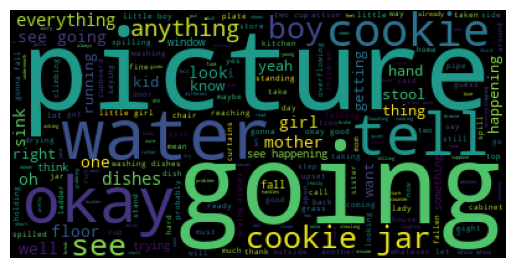

[('picture', 102), ('going', 100), ('water', 98), ('okay', 80), ('tell', 69), ('cookie', 63), ('cookie jar', 59), ('see', 58), ('boy', 57), ('anything', 56), ('everything', 52), ('dishes', 52), ('mother', 46), ('sink', 45), ('look', 44), ('see going', 42), ('girl', 41), ('oh', 41), ('one', 38), ('floor', 36), ('well', 36), ('running', 33), ('happening', 32), ('kid', 30), ('hand', 28), ('right', 27), ('know', 26), ('getting', 25), ('yeah', 24), ('want', 24), ('stool', 24), ('thing', 23), ('see happening', 23), ('trying', 22), ('fall', 22), ('something', 21), ('window', 21), ('think', 21), ('washing dishes', 21), ('falling', 20), ('say', 18), ('now', 18), ('plate', 17), ('action', 17), ('little girl', 17), ('okay good', 17), ('still', 16), ('go', 15), ('washing', 15), ('chair', 15)]


In [206]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(text for _, text in train_data["ad"])
print(ad_top_words[:50])
ad_top_words_set = set([w for w, count in ad_top_words[:200]])

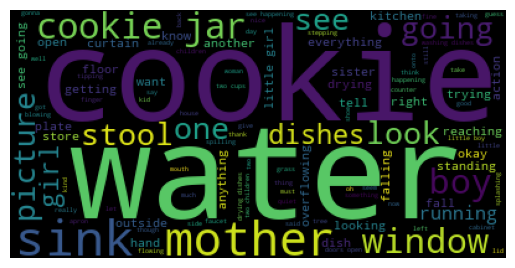

[('water', 102), ('cookie', 97), ('sink', 85), ('mother', 75), ('cookie jar', 75), ('boy', 71), ('window', 69), ('stool', 54), ('see', 53), ('picture', 53), ('going', 53), ('one', 52), ('look', 52), ('dishes', 51), ('girl', 46), ('running', 46), ('everything', 45), ('okay', 41), ('reaching', 40), ('getting', 38), ('tell', 38), ('floor', 37), ('hand', 35), ('drying', 34), ('overflowing', 33), ('right', 32), ('curtain', 31), ('standing', 30), ('open', 29), ('falling', 28), ('fall', 26), ('sister', 26), ('want', 24), ('little girl', 24), ('action', 23), ('plate', 22), ('anything', 21), ('see going', 21), ('know', 20), ('looking', 20), ('kitchen', 20), ('trying', 20), ('outside', 19), ('dish', 19), ('another', 19), ('store', 19), ('washing dishes', 18), ('onto', 17), ('thing', 17), ('little boy', 17)]


In [207]:
# see the most frequent words of CN (negative) group
cn_top_words = make_wordcloud([text for _, text in train_data["cn"]])
print(cn_top_words[:50])
cn_top_words_set = set([w for w, count in cn_top_words[:200]])

In [208]:
# observe the difference in 2 word set
ad_unique = ad_top_words_set - cn_top_words_set
cn_unique = cn_top_words_set - ad_top_words_set
print("AD unique words =\n", ad_unique)
print("----------------")
print("CN unique words =\n", cn_unique)

AD unique words =
 {'whoa whoa', 'ha', 'share', 'young', 'find', 'stove', 'fell', 'two cup', 'broke', 'touching', 'read', 'spilled', 'grabbing', 'gotta', 'stealing', 'stone', 'cooking', 'underneath', 'stand', 'love', 'lot', 'made', 'small', 'curtains', 'okay good', 'almost', 'spill', 'breeze', 'assume', 'always', 'cup', 'saucer', 'guy', 'put', 'telling', 'wash', 'yes', 'next', 'break', 'suppose', 'home', 'neck', 'rather', 'somebody', 'upset', 'step', 'eat', 'new', 'told', 'problem', 'third', 'working', 'taken', 'try', 'bushes', 'ladder', 'goes', 'whatever', 'sorry', 'whether', 'pipe', 'slipping', 'watching', 'given', 'us', 'pretty', 'shoes', 'hard', 'lady', 'handles', 'different', 'call'}
----------------
CN unique words =
 {'course', 'wiping', 'finger', 'handing', 'drawing', 'brother', 'stealing cookies', 'mouth', 'walking', 'behind', 'flowing', 'grab', 'tie', 'start', 'lip', 'towel', 'appear', 'son', 'dress', 'paying', 'crash', 'giving', 'garden', 'full', 'face', 'foot', 'show', 'mam

In [209]:
# combine data into a dataframe, for export to a csv for further processing

def combine_data(train_data):
    train_dict = {
        "text": [],  # the transcript
        "target": [],  # the target: positive (AD), negative (CN)
        "file": [],
    }
    for item in train_data["ad"]:
        train_dict["text"].append(item[1])
        train_dict["file"].append(item[0])
        train_dict["target"].append("AD")

    for item in train_data["cn"]:
        train_dict["text"].append(item[1])
        train_dict["file"].append(item[0])
        train_dict["target"].append("CN")

    print("Text count =", len(train_dict["text"]))
    print("Target count =", len(train_dict["target"]))
    return train_dict


train_dict = combine_data(train_data)

Text count = 166
Target count = 166


In [210]:
train_df = pd.DataFrame(train_dict)
# merge mmse scores onto train df
train_df = train_df.merge(mmse_df, left_on="file", right_on="adressfname")[
    ["text", "target", "mmse"]
]
print(len(train_df))
train_df.head()

166


,text,target,mmse
0,The cookie jar and the little\n\n\n\nboy about...,AD,20
1,Tell me everything that's going on\n\n\n\nthe ...,AD,11
2,As a picture little girl and a little boy stan...,AD,18
3,She will find her mother worship trying to dis...,AD,18
4,What do you see going on\n\n\n\nthe boys on a ...,AD,26


In [211]:
train_df[["text", "target"]].describe()

,text,target
count,166,166
unique,166,2
top,The cookie jar and the little\n\n\n\nboy about...,AD
freq,1,87


In [212]:
train_df[["mmse"]].describe()

,mmse
count,166.000000
mean,22.933735
std,6.992754
min,3.000000
25%,17.250000
50%,26.000000
75%,29.000000
max,30.000000


We can see we have total of 166 examples, with 87 positive (AD) and 79 negative (CN). The train_set is relatively balanced. 

In [213]:
train_df.groupby("target")[["mmse"]].agg(["count", "min", "mean", "median", "max"])

mmse                          
       count min       mean median max
target                                
AD        87   3  17.436782   18.0  28
CN        79  26  28.987342   29.0  30

We also see that the MMSE, which evaluates the presence and severity of cognitive impairment, is drastically higher for the CN group than the AD group for both the median and mean, which is to be expected.

Now we can split the data into train and dev set

In [214]:
train_df, dev_df = train_test_split(train_df, test_size=0.5, random_state=42)
print("train len =", len(train_df))
print("dev len =", len(dev_df))

train len = 83
dev len = 83


In [215]:
train_df.head()

,text,target,mmse
79,I think you see going on in that picture. We'l...,AD,11
39,I'm gonna give you a picture that has a lot of...,AD,12
154,Ah the sinks running over waters come on all f...,CN,30
86,"Well, my boys trying to get some cookies and t...",AD,15
117,I'd like you to do is just look at the picture...,CN,27


In [216]:
dev_df.head()

,text,target,mmse
100,"Everything you see going on in this picture, g...",CN,28
136,"Now you just look at the picture. Okay, this i...",CN,30
78,Tell me everything that you see going on in th...,AD,20
56,Girls and boys getting her one that stores sto...,AD,20
97,"All right, we have a few more tasks to go thro...",CN,30


In [217]:
# write to csv
path = "../data/splits/"

In [218]:
print("Writing to csv files...")
train_df.to_csv(path + "train.csv", index=False)
dev_df.to_csv(path + "dev.csv", index=False)
print("Completed")

Writing to csv files...
Completed


## Pitt Dataset

Import Pitt dataset along with Pitt MMSE scores. After cleaning the MMSE scores, merge the two datasets together.

In [329]:
pitt_train_data = {"ad": [], "cn": []}

In [330]:
pitt_path_ad = "../data/TalkBank downloads/Pitt/Dementia/Cookie/"
pitt_path_cn = "../data/TalkBank downloads/Pitt/Control/Cookie/"

In [331]:
format = "cha"
pitt_train_data["ad"] = read_data(pitt_path_ad, format, True)
pitt_train_data["cn"] = read_data(pitt_path_cn, format, True)

Processing files = 001-0.cha
Line len = 85
Processing files = 001-2.cha
Line len = 125
Processing files = 003-0.cha
Line len = 172
Processing files = 005-0.cha
Line len = 73
Processing files = 005-2.cha
Line len = 92
Processing files = 007-1.cha
Line len = 105
Processing files = 007-3.cha
Line len = 85
Processing files = 010-0.cha
Line len = 186
Processing files = 010-1.cha
Line len = 201
Processing files = 010-2.cha
Line len = 208
Processing files = 010-3.cha
Line len = 128
Processing files = 010-4.cha
Line len = 92
Processing files = 014-2.cha
Line len = 161
Processing files = 016-0.cha
Line len = 65
Processing files = 016-1.cha
Line len = 57
Processing files = 016-3.cha
Line len = 62
Processing files = 016-4.cha
Line len = 108
Processing files = 018-0.cha
Line len = 199
Processing files = 023-0.cha
Line len = 91
Processing files = 023-2.cha
Line len = 129
Processing files = 024-1.cha
Line len = 68
Processing files = 024-2.cha
Line len = 91
Processing files = 029-0.cha
Line len = 114

In [332]:
# double check data
assert len(pitt_train_data["ad"]) == 306
assert len(pitt_train_data["cn"]) == 243
assert pitt_train_data["ad"][0][1].startswith("mhm")
assert pitt_train_data["ad"][1][1].startswith("mhm")
assert pitt_train_data["cn"][0][1].startswith("the scene is <in the>")
assert pitt_train_data["cn"][1][1].startswith("oh I see the sink is running over")
print("Passed")

Passed


In [333]:
pitt_mmse_scores_fname = "../data/TalkBank downloads/Pitt/Pitt-data.xlsx"
pitt_mmse_df = pd.read_excel(
    pitt_mmse_scores_fname,
    sheet_name="data",
    header=2,
    usecols=["id", "mms", "mmse2", "mmse3", "mmse4", "mmse5"],
)

/Users/la/miniconda3/envs/mds/lib/python3.11/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [334]:
pitt_mmse_df = pitt_mmse_df.rename(columns={"mms": "mmse1"})
pitt_mmse_df = pd.wide_to_long(
    pitt_mmse_df, i="id", j="interview_number", stubnames="mmse"
).reset_index()
pitt_mmse_df["id"] = pitt_mmse_df["id"].astype(str).str.pad(width=3, fillchar="0")
pitt_mmse_df["interview_number"] = pitt_mmse_df["interview_number"] - 1
pitt_mmse_df["id"] = (
    pitt_mmse_df["id"] + "-" + pitt_mmse_df["interview_number"].astype(str)
)
pitt_mmse_df = pitt_mmse_df[["id", "mmse"]]
pitt_mmse_df = pitt_mmse_df[~pitt_mmse_df["mmse"].isnull()]
pitt_mmse_df

,id,mmse
0,001-0,18.0
1,002-0,30.0
2,003-0,20.0
3,005-0,23.0
4,006-0,28.0
...,...,...
2470,621-4,10.0
2479,631-4,28.0
2502,663-4,19.0
2516,681-4,19.0


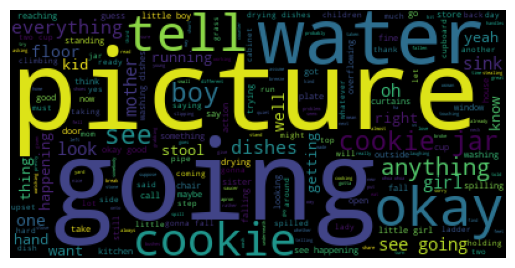

In [335]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(text for _, text in train_data["ad"])
ad_top_words_set = set([w for w, count in ad_top_words[:200]])

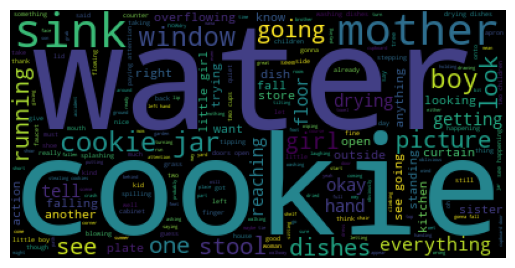

In [336]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(text for _, text in train_data["cn"])
ad_top_words_set = set([w for w, count in ad_top_words[:200]])

In [337]:
# observe the difference in 2 word set
ad_unique = ad_top_words_set - cn_top_words_set
cn_unique = cn_top_words_set - ad_top_words_set
print("AD unique words =\n", ad_unique)
print("----------------")
print("CN unique words =\n", cn_unique)

AD unique words =
 set()
----------------
CN unique words =
 set()


In [338]:
pitt_train_dict = combine_data(pitt_train_data)

Text count = 549
Target count = 549


In [346]:
pitt_train_df = pd.DataFrame(pitt_train_dict)
pitt_train_df["id"] = pitt_train_df["file"].str.split(".").str[0]

In [347]:
pitt_train_df = pitt_train_df.merge(
    pitt_mmse_df, left_on="id", right_on="id", how="inner"
)[["id", "file", "target", "text", "mmse"]]
pitt_train_df

,id,file,target,text,mmse
0,001-0,001-0.cha,AD,mhm .\nalright .\nthere's &-um a young boy tha...,18.0
1,001-2,001-2.cha,AD,mhm .\nthere's a young boy &-uh going in a coo...,11.0
2,003-0,003-0.cha,AD,here's a cookie jar .\nand the lid is off the ...,20.0
3,005-0,005-0.cha,AD,the boy is slipping off the stool .\nhe's tryi...,23.0
4,005-2,005-2.cha,AD,okay ‡ he's fallin(g) off a chair .\nshe's &-...,19.0
...,...,...,...,...,...
453,684-0,684-0.cha,CN,uh the boy is reaching into the cookie jar .\n...,30.0
454,686-0,686-0.cha,CN,well the little girl is reaching for a cookie ...,30.0
455,688-0,688-0.cha,CN,mhm .\nmhm a_lot_of things are happening .\nye...,28.0
456,691-0,691-0.cha,CN,alright .\nthe little boy girl's reaching up ...,29.0


In [351]:
comb_train_df = pd.concat([train_df, pitt_train_df])[["id", "text", "mmse", "target"]]
comb_train_df

,id,text,mmse,target
153,NaN,Children are getting cookies stored during the...,28.0,CN
150,NaN,Tell me everything that you see going on in th...,28.0,CN
39,NaN,I'm gonna give you a picture that has a lot of...,12.0,AD
165,NaN,I'd love you to tell me everything that you se...,30.0,CN
46,NaN,What's your take a look at this picture. Tell ...,8.0,AD
...,...,...,...,...
453,684-0,uh the boy is reaching into the cookie jar .\n...,30.0,CN
454,686-0,well the little girl is reaching for a cookie ...,30.0,CN
455,688-0,mhm .\nmhm a_lot_of things are happening .\nye...,28.0,CN
456,691-0,alright .\nthe little boy girl's reaching up ...,29.0,CN


In [353]:
comb_train_df, comb_dev_df = train_test_split(
    comb_train_df, test_size=0.2, random_state=42
)

print("train len =", len(comb_train_df))
print("dev len =", len(comb_dev_df))

train len = 348
dev len = 88


In [354]:
print("Writing to csv files...")

comb_train_df.to_csv(path + "train_combined.csv", index=False)
comb_dev_df.to_csv(path + "dev_combined.csv", index=False)

print("Completed")

Writing to csv files...
Completed
